# Robustness: Fig. 5

The sensitivity and ablation panels are traced to the archived evaluation CSV files. Their scores are read directly; no parameter sweep is run.

Read the stored outputs below in order. These cells load and plot archived results; they do not preprocess inputs, train models, cluster spots, or fit a new UMAP/t-SNE.

Data: `Published_Data_non_NASH/01_Mouse_E15_5/`. The sharedoc download link will be added after the archive is uploaded.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Reproduce").is_dir())
sys.path.insert(0, str(repo / "Reproduce"))
from _shared.paper_plots import *
DATA_ROOT = Path(os.environ.get("MELON_PUBLISHED_DATA", repo / "Published_Data_non_NASH"))
DATA = DATA_ROOT / "01_Mouse_E15_5"
assert DATA.is_dir(), "Place Published_Data_non_NASH beside Reproduce, or set MELON_PUBLISHED_DATA."


## 1. Read the saved sensitivity scores — Fig. 5a-b

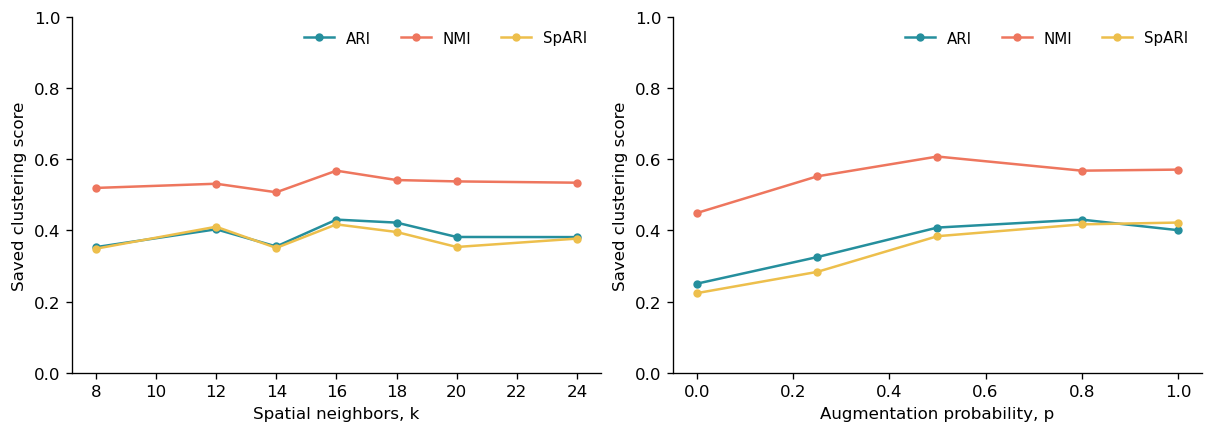

In [2]:
RESULTS = DATA / "05_Fig5_robustness"
neighbors = pd.read_csv(RESULTS / "neighbor_k_local_report_metrics.csv")
augmentation = pd.read_csv(RESULTS / "augment_p_report_metrics.csv")
show(sensitivity_panels(neighbors, augmentation))

## 2. Inspect the archived ablation sweep

The input contains an existing cluster-number sweep. Bars are medians and error bars are its 25th and 75th percentiles. **This archived table does not reproduce the final Fig. 5c bars**: its full-model median ARI is 0.383, while the supplied manuscript panel is approximately 0.48. The final panel source requires reconciliation; the manuscript image below is unchanged.

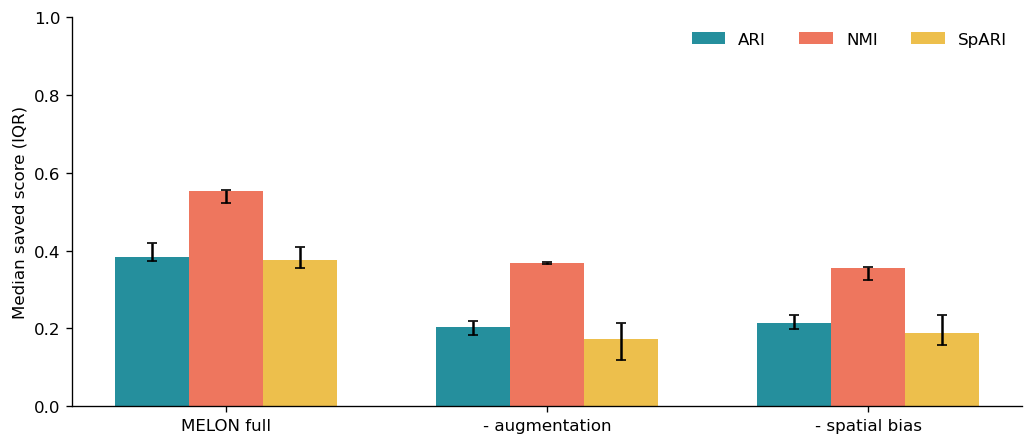

In [3]:
ablation = pd.read_csv(RESULTS / "ablation_multik_metrics_E15.csv")
show(ablation_panels(ablation))

## Corresponding manuscript figure

Panels **a-b** are neighborhood/augmentation sensitivity, **c** is component ablation, and **d-f** compare integrated ARI with the best single modality for E15.5, lymph node and E13.

![Manuscript Figure 5](../figures/paper_figure_5.png)

*Original manuscript figure, supplied PDF dated 2026-11-03. The notebook plots above are views of the saved data, not a replacement for this assembled figure.*

## Panel sources

| Panels | Source |
| --- | --- |
| 5a | `05_Fig5_robustness/neighbor_k_local_report_metrics.csv` |
| 5b | `05_Fig5_robustness/augment_p_report_metrics.csv` |
| Related ablation sweep | `05_Fig5_robustness/ablation_multik_metrics_E15.csv`; differs from the final Fig. 5c summary |
| 5d-f | Each tissue archive contains final integrated/single-modality labels; the final fusion-gain summary table is separate |

Saved sensitivity embeddings and labels remain alongside the score tables for tracing each run. This walkthrough does not recompute evaluation scores from them.